## 09.Final Model Selection and Evaluation



### Objective

The objective of this stage is to evaluate the tuned machine learning models using the unseen test dataset.
We compare the models using accuracy, precision, recall, F1-score, ROC-AUC score and confusion matrix.
The best-performing model will be selected for the next stage of the project.

In [ ]:
### Importing Required Libraries
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [2]:
# Load saved models and test data
saved_data = joblib.load(
    "../models/tuned_models_and_test_data.pkl"
)

best_models = saved_data["best_models"]
X_test = saved_data["X_test"]
y_test = saved_data["y_test"]

print("Tuned models loaded successfully!")
print("Test data shape:", X_test.shape)
print("Number of models:", len(best_models))

Tuned models loaded successfully!
Test data shape: (79, 30)
Number of models: 5


### 9.1 Evaluating the Tuned Models

Each tuned model makes predictions on the unseen test dataset.

We calculate accuracy, precision, recall, F1-score and ROC-AUC score.

The Pass class is treated as the positive class for precision, recall and ROC-AUC.

In [3]:
# Store evaluation results
final_results = []

# Store predictions for later use
final_predictions = {}

# Evaluate each tuned model
for name, model in best_models.items():

    # Make predictions
    predictions = model.predict(X_test)

    # Store predictions
    final_predictions[name] = predictions

    # Calculate ROC-AUC score
    if hasattr(model, "predict_proba"):
        pass_index = list(model.classes_).index("Pass")
        scores = model.predict_proba(X_test)[:, pass_index]

    else:
        scores = model.decision_function(X_test)

    auc = roc_auc_score(
        (y_test == "Pass").astype(int),
        scores
    )

    # Calculate evaluation metrics
    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            pos_label="Pass",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            pos_label="Pass",
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions,
            pos_label="Pass",
            zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "ROC-AUC": auc
    })

    print(name, "evaluation completed!")

Decision Tree evaluation completed!
Random Forest evaluation completed!
SVM evaluation completed!
KNN evaluation completed!
MLP evaluation completed!


### 9.2 Comparing Model Performance

We create a comparison table to display the evaluation metrics of all five tuned models.

The models are compared using their accuracy, precision, recall, F1-score, macro F1-score and ROC-AUC score.

In [4]:
# Create comparison DataFrame
final_results_df = pd.DataFrame(final_results)

# Sort models by macro F1-score
final_results_df = final_results_df.sort_values(
    by="Macro F1-score",
    ascending=False
)

# Display results
display(final_results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-score,Macro F1-score,ROC-AUC
0,Decision Tree,0.684,0.769,0.755,0.762,0.645,0.647
4,MLP,0.608,0.704,0.717,0.710,0.551,0.610
2,SVM,0.671,0.690,0.925,0.790,0.513,0.594
3,KNN,0.633,0.682,0.849,0.756,0.506,0.566
1,Random Forest,0.633,0.676,0.868,0.760,0.488,0.634


### 9.3 Confusion Matrix

A confusion matrix shows the number of correct and incorrect predictions made by a classification model.

It contains four values:

- True Positive: Actual Pass predicted as Pass.
- True Negative: Actual Fail predicted as Fail.
- False Positive: Actual Fail predicted as Pass.
- False Negative: Actual Pass predicted as Fail.

We use confusion matrices to understand the prediction performance of each model.

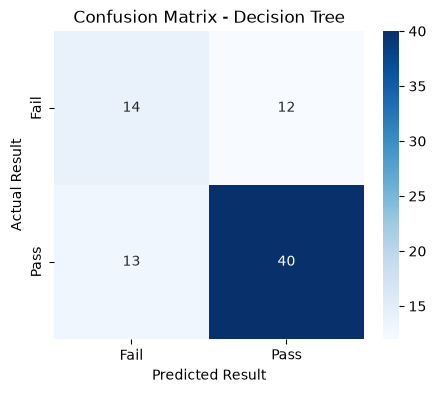

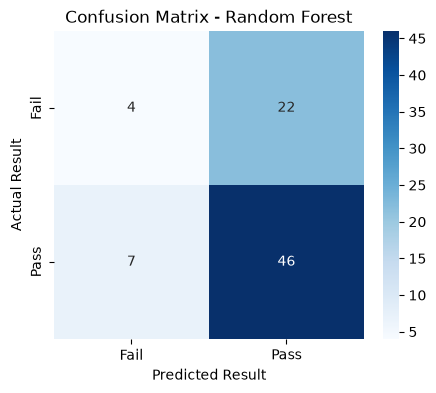

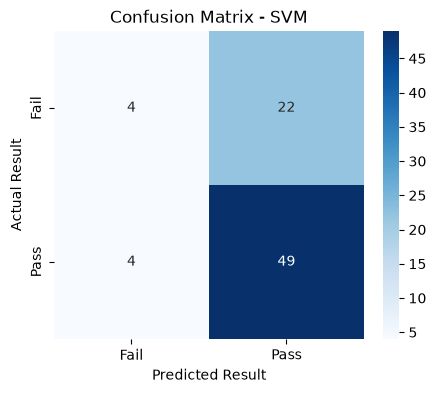

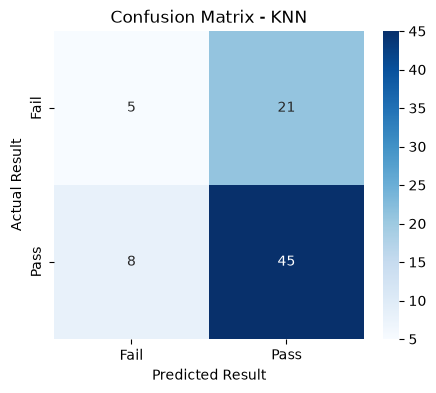

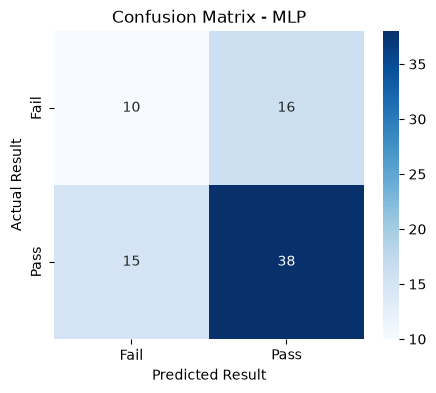

In [5]:
# Display confusion matrix for each model
for name, predictions in final_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["Fail", "Pass"]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fail", "Pass"],
        yticklabels=["Fail", "Pass"]
    )

    plt.xlabel("Predicted Result")
    plt.ylabel("Actual Result")
    plt.title("Confusion Matrix - " + name)

    plt.show()

### 9.4 Classification Report

The classification report provides precision, recall, F1-score and support for both Pass and Fail classes.

It helps us understand how well each model predicts individual classes.

In [6]:
# Display classification report for each model
for name, predictions in final_predictions.items():

    print("\nClassification Report for", name)

    print(
        classification_report(
            y_test,
            predictions,
            labels=["Fail", "Pass"],
            zero_division=0
        )
    )


Classification Report for Decision Tree
              precision    recall  f1-score   support

        Fail       0.52      0.54      0.53        26
        Pass       0.77      0.75      0.76        53

    accuracy                           0.68        79
   macro avg       0.64      0.65      0.65        79
weighted avg       0.69      0.68      0.69        79


Classification Report for Random Forest
              precision    recall  f1-score   support

        Fail       0.36      0.15      0.22        26
        Pass       0.68      0.87      0.76        53

    accuracy                           0.63        79
   macro avg       0.52      0.51      0.49        79
weighted avg       0.57      0.63      0.58        79


Classification Report for SVM
              precision    recall  f1-score   support

        Fail       0.50      0.15      0.24        26
        Pass       0.69      0.92      0.79        53

    accuracy                           0.67        79
   macro avg   

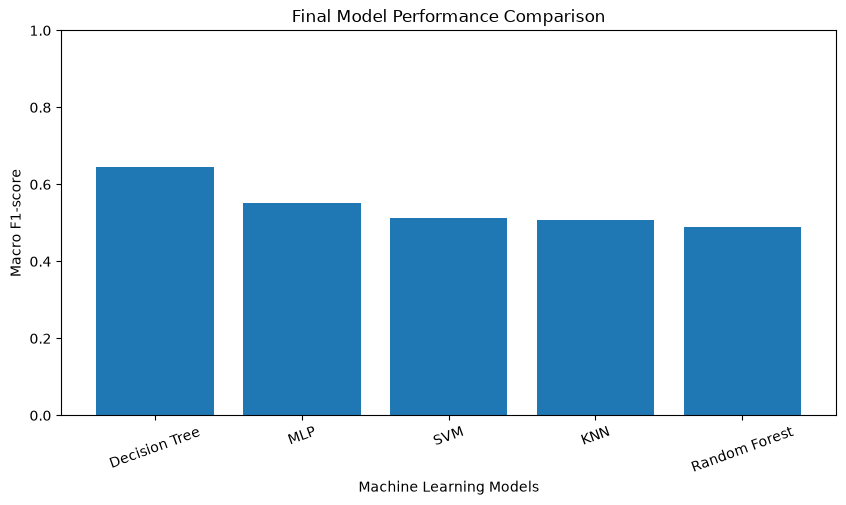

In [7]:
### 9.8 Visualizing Final Model Performance
plt.figure(figsize=(10, 5))

plt.bar(
    final_results_df["Model"],
    final_results_df["Macro F1-score"]
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Macro F1-score")
plt.title("Final Model Performance Comparison")

plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.show()

### 9.5 Selecting the Best Model

The models are compared using their test performance.

The model with the highest macro F1-score is identified as the best-performing model based on this evaluation.

Its performance is also checked using accuracy, precision, recall, ROC-AUC and the confusion matrix.

In [9]:
# Select model with highest macro F1-score
best_model_name = final_results_df.iloc[0]["Model"]

best_model = best_models[best_model_name]

print("Best Performing Model:", best_model_name)

print(
    "Best Macro F1-score:",
    round(final_results_df.iloc[0]["Macro F1-score"], 3)
)

Best Performing Model: Decision Tree
Best Macro F1-score: 0.645


Hence we can conclude from this that the five tuned machine learning models were evaluated using the unseen test dataset.

Accuracy, precision, recall, F1-score, ROC-AUC and confusion matrices were used to compare their performance.

The best-performing model was selected based on its macro F1-score and overall classification performance.

The selected model (i.e. Decision Tree) will be saved and used in the Student Academic Performance Prediction web application.

## SAVING THE FINAL MODEL

In this section, the best-performing tuned machine learning model is saved for future use.

The complete model pipeline, including preprocessing, is saved using Joblib. This allows us to reuse the model without training it again.

In [11]:
# Import required libraries
import joblib
import os


In [13]:
# Select the model with the highest Macro F1-score
best_model_name = final_results_df.iloc[0]["Model"]

# Retrieve the selected model
best_model = best_models[best_model_name]

print("Best Performing Model:", best_model_name)

print(
    "Best Macro F1-score:",
    round(final_results_df.iloc[0]["Macro F1-score"], 3)
)


Best Performing Model: Decision Tree
Best Macro F1-score: 0.645


In [14]:
# Create the models folder if it does not exist
os.makedirs("../models", exist_ok=True)

print("Models folder is ready!")


Models folder is ready!


In [15]:
# Save the complete selected model pipeline
joblib.dump(
    best_model,
    "../models/best_student_performance_model.pkl"
)

print("Best model saved successfully!")


Best model saved successfully!


In [16]:
# Load the saved model
loaded_model = joblib.load(
    "../models/best_student_performance_model.pkl"
)

print("Saved model loaded successfully!")


Saved model loaded successfully!


In [17]:
# Make predictions using the loaded model
sample_predictions = loaded_model.predict(X_test.head(5))

print("Sample Predictions:")
print(sample_predictions)


Sample Predictions:
['Pass' 'Pass' 'Pass' 'Pass' 'Pass']


## Conclusion

The best-performing tuned Decision Tree model was saved successfully using Joblib.

The complete preprocessing and prediction pipeline was preserved. The saved model was loaded again and tested to verify that it can make predictions without requiring retraining.

This saved model will be used in the future Streamlit application.